# P0. Re-mine old runs

Do repeated runs of the same DiscoveryBench task split at analysis decisions, and at which types? This notebook recomputes the numbers in `quick_runs/results/P0/report.md` from the run list (`run_folders.csv`), the per-run facts and the cached extractor replies under `/data/anon/reveries_runs/P0/`, and checks them against `summary.json`.

Caveat: the runs of one task differ by arm (memory, retrieval, corrector, design discipline) and by code version, not only by seed.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
REPO = Path.cwd().resolve()
while not (REPO / 'quick_runs').is_dir():
    REPO = REPO.parent
for p in (REPO, REPO / 'quick_runs', REPO / 'quick_runs' / 'p0'):
    sys.path.insert(0, str(p))
import agree
runs = pd.read_csv(REPO / 'quick_runs/results/P0/run_folders.csv')
print(runs.why.value_counts().to_string())
inc = runs[runs.included]
print('included runs per task:', inc.groupby('task').size().to_dict())
print(inc.arm.value_counts().to_string())

why
excluded: scoring twin (symlinks the generation run's provenance; same run)    263
included: task run 3 times with executed code                                   42
included: task run 9 times with executed code                                   36
included: task run 6 times with executed code                                   30
included: task run 11 times with executed code                                  11
included: task run 5 times with executed code                                    5
included runs per task: {0: 3, 1: 6, 2: 9, 3: 9, 4: 3, 5: 11, 6: 3, 7: 6, 8: 3, 9: 3, 10: 3, 11: 3, 12: 6, 13: 6, 14: 3, 15: 9, 16: 5, 17: 3, 18: 9, 19: 3, 20: 6, 21: 3, 22: 3, 23: 3, 24: 3}
arm
v8_transfer:mem_all_graphon_refsum_v8    25
v8_transfer:mem_all_graphon_v8           25
v8_transfer:mem_off_v8                   25
v10_stage2:base_v10_v10h                  5
v10_stage2:c_v10_v10h                     5
v10_stage2:c_v10_v10kph                   5
v10_stage1:base_v10_v10                

## Recompute agreement from the cached extractor replies

In [2]:
recs, failed = agree.load_records(inc)
print(len(recs), 'runs extracted; failures:', failed)
results = {s: agree.analyse(recs, s) for s in agree.SUBSETS}
saved = json.loads((REPO / 'quick_runs/results/P0/summary.json').read_text())
assert json.loads(json.dumps(results)) == saved['results'], 'recomputed agreement differs from summary.json'
assert len(recs) == saved['n_extracted']
print('recomputed agreement matches summary.json')

124 runs extracted; failures: []
recomputed agreement matches summary.json


In [3]:
def pooled_table(subset):
    df = pd.DataFrame(results[subset]['pooled']).set_index('type')
    return df.round(3)
print('all runs:', results['all']['n_runs'], 'runs,', results['all']['n_tasks'], 'tasks')
pooled_table('all')

all runs: 124 runs, 25 tasks


,tasks_with_2plus_values,mean_agreement_over_tasks,pair_weighted_agreement,tasks_all_runs_same,tasks_all_runs_differ
type,,,,,
framing.target,25,0.737,0.813,14,1
framing.population,25,0.070,0.117,0,18
framing.unit,25,0.674,0.598,12,0
variables,25,0.223,0.181,2,8
transformation,25,0.097,0.092,0,14
model.family,25,0.791,0.874,17,0
model.controls,25,0.275,0.113,5,10
validation,25,1.000,1.000,25,0
metric,25,0.778,0.902,16,2


In [4]:
print('v8 only:', results['v8_only']['n_runs'], 'runs')
pooled_table('v8_only')

v8 only: 75 runs


,tasks_with_2plus_values,mean_agreement_over_tasks,pair_weighted_agreement,tasks_all_runs_same,tasks_all_runs_differ
type,,,,,
framing.target,25,0.800,0.800,18,1
framing.population,25,0.053,0.053,0,21
framing.unit,25,0.693,0.693,14,1
variables,25,0.200,0.200,2,14
transformation,25,0.120,0.120,1,18
model.family,25,0.840,0.840,19,0
model.controls,25,0.360,0.360,7,12
validation,25,1.000,1.000,25,0
metric,25,0.733,0.733,16,2


In [5]:
print('split most (all):', results['all']['split_most'])
print('split most (v8 only):', results['v8_only']['split_most'])
print('split most (v10 only):', results['v10_only']['split_most'])
print('first divergence (all):', results['all']['first_divergence_counts'])

split most (all): ['final_selection', 'framing.population', 'transformation']
split most (v8 only): ['final_selection', 'framing.population', 'transformation']
split most (v10 only): ['model.controls', 'transformation', 'final_selection']
first divergence (all): {'framing.population': 14, 'framing.target': 11}


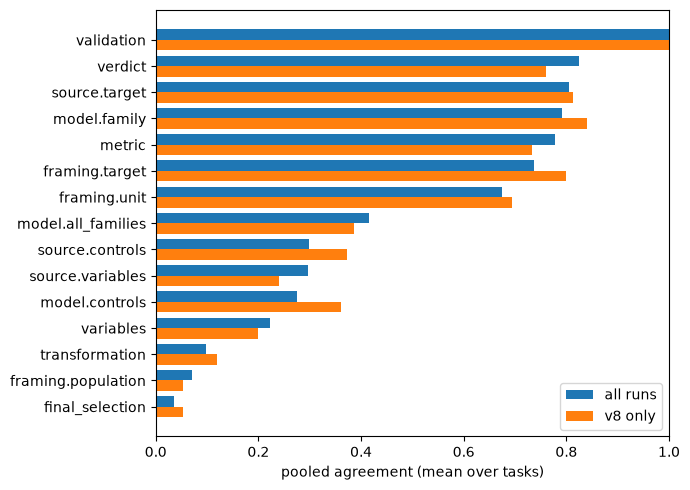

In [6]:
import matplotlib.pyplot as plt
df = pd.DataFrame(results['all']['pooled']).set_index('type')['mean_agreement_over_tasks']
df8 = pd.DataFrame(results['v8_only']['pooled']).set_index('type')['mean_agreement_over_tasks']
order = df.sort_values().index
fig, ax = plt.subplots(figsize=(7, 5))
y = range(len(order))
ax.barh([i + 0.2 for i in y], df[order], height=0.4, label='all runs')
ax.barh([i - 0.2 for i in y], df8[order], height=0.4, label='v8 only')
ax.set_yticks(list(y)); ax.set_yticklabels(order); ax.set_xlim(0, 1)
ax.set_xlabel('pooled agreement (mean over tasks)'); ax.legend(); plt.tight_layout()

## Per-task agreement (all runs)

In [7]:
pd.DataFrame(results['all']['per_task']).set_index('task').round(2)

,n_runs,framing.target,framing.population,framing.unit,variables,transformation,model.family,model.controls,validation,metric,verdict,final_selection,source.target,source.variables,source.controls,model.all_families,first_divergence
task,,,,,,,,,,,,,,,,,
0,3,1.00,0.00,0.33,0.33,0.00,1.00,0.00,1.0,0.33,1.00,0.00,1.00,0.33,0.00,0.33,framing.population
1,6,1.00,0.00,0.47,0.07,0.00,1.00,0.00,1.0,1.00,0.60,0.07,1.00,0.13,0.00,0.40,framing.population
2,9,1.00,0.28,1.00,0.28,0.08,1.00,0.11,1.0,1.00,1.00,0.28,1.00,0.31,0.17,0.58,framing.population
3,9,1.00,0.42,1.00,0.42,0.11,0.50,0.11,1.0,0.78,0.78,0.03,1.00,0.42,0.17,0.44,framing.population
4,3,1.00,0.00,0.33,0.00,0.00,1.00,0.00,1.0,1.00,1.00,0.00,1.00,0.00,0.00,0.00,framing.population
5,11,1.00,0.00,0.67,0.07,0.02,1.00,0.05,1.0,1.00,1.00,0.02,1.00,0.11,0.13,1.00,framing.population
6,3,1.00,0.00,0.33,0.33,0.00,1.00,0.33,1.0,1.00,1.00,0.00,1.00,0.33,0.33,0.33,framing.population
7,6,1.00,0.00,0.27,0.00,0.00,0.27,0.00,1.0,1.00,1.00,0.00,1.00,0.40,0.00,0.07,framing.population
8,3,1.00,0.00,1.00,0.00,0.00,1.00,0.00,1.0,1.00,0.33,0.00,1.00,0.00,0.00,0.33,framing.population


## Example extracted decisions for one task (to eyeball the extractor)

In [8]:
t = 5
pd.set_option('display.max_colwidth', 80)
pd.DataFrame({r['arm']: r['decisions'] for r in recs.values() if r['task'] == t}).T

,framing.target,framing.population,framing.unit,variables,transformation,model.family,model.controls,validation,metric,verdict,final_selection,model.all_families,source.target,source.variables,source.controls
e01:mem_all_graphon_corr_e0_dbg,dissaved,"drop rows with missing dissaved, age, log_income, black, hispanic, gender_bin",respondent,age|log_income,derive:gender_bin|derive:log_income|dropna:all|interaction:age:log_income|lo...,logistic,black|gender_bin|hispanic,none,coefficient_and_p,supported,logit model with interaction and controls,logistic,dissaved,age|income,black|gender|hispanic
e01:mem_all_graphon_corr_e1_dbg,dissaved,"drop rows with missing dissaved, age, log_income, gender_bin, black, hispanic",respondent,age|log_income,derive:log_income|dropna:all|interaction:age:log_income|other:gender_bin,logistic,black|gender_bin|hispanic,none,coefficient_and_p,supported,logit model with interaction,logistic,dissaved,age|income,black|gender|hispanic
v10_stage1:base_v10_v10,dissaved,drop rows with missing x,respondent,age|age_2|log_income,derive:log_income|dropna:all|one_hot:gender,logistic,black|gender|hispanic,none,coefficient_and_p,supported,logit,logistic,dissaved,age|age_2|income,black|gender|hispanic
v10_stage1:k_v10_v10,dissaved,"drop rows with missing dissaved, age, age_2, log_income, gender, black, hisp...",respondent,age|age_2,derive:log_income|dropna:all|label_encode:gender,logistic,black|gender|hispanic|log_income,none,coefficient_and_p,supported,logit model,logistic,dissaved,age|age_2,black|gender|hispanic|income
v10_stage1:p_v10_v10,dissaved,"drop rows with missing dissaved, age, age_2, income, gender, bmi, black, his...",respondent,age_2,derive:gender_bin|dropna:all|to_numeric:black|to_numeric:dissaved|to_numeric...,logistic,age|black|bmi|gender_bin|hispanic|income,none,coefficient_and_p,supported,logit_model,logistic,dissaved,age_2,age|black|bmi|gender|hispanic|income
v10_stage1:r_v10_v10,dissaved,"drop rows with missing dissaved, age, gender, income",respondent,age,derive:log_income|dropna:all|one_hot:gender,logistic,gender_dummy|log_income,none,coefficient_and_p,supported,logit,logistic,dissaved,age,gender|income
v10_stage2:c_v10_v10,dissaved,"drop rows with missing dissaved, age, gender_bin, income, black, hispanic, bmi",respondent,age|gender_bin,derive:gender_bin|dropna:all|interaction:age*gender_bin|to_numeric:black|to_...,logistic,black|bmi|hispanic|income,none,coefficient_and_p,supported,logit(dissaved) ~ age * gender_bin + income + black + hispanic + bmi,logistic,dissaved,age|gender,black|bmi|hispanic|income
v10_stage2:c_v10_v10kp,dissaved,"drop rows with missing dissaved, age, bmi, black, hispanic, income, gender_num",respondent,age,derive:gender_num|dropna:all|to_numeric:black|to_numeric:dissaved|to_numeric...,logistic,black|bmi|gender_num|hispanic|income,none,coefficient_and_p,supported,logit model (dissaved ~ age + bmi + black + hispanic + income + gender_num),logistic,dissaved,age,black|bmi|gender|hispanic|income
v8_transfer:mem_all_graphon_refsum_v8,dissaved,"drop rows with missing age, income, dissaved and age between 24 and 32",respondent,age|income_group,"derive:income_group|dropna:['age', 'income', 'dissaved']",logistic,(none),none,coefficient_and_p,supported,logistic regression (dissaved ~ age * income_group),logistic,dissaved,age|income,(none)
v8_transfer:mem_all_graphon_v8,dissaved,age >= 24 and age <= 32,individual,age_std|bmi_std|gender|income_std,"derive:age_std|derive:bmi_std|derive:income_std|dropna:['age', 'bmi', 'incom...",logistic,black|gender|hispanic,none,coefficient_and_p,supported,logistic regression with three-way interaction,logistic,dissaved,age|bmi|gender|income,black|gender|hispanic


## What the old memory showed the agent (descriptive)

Rules (see `quick_runs/p0/memory_use.py`): a code memory is *followed* when the next code has the same design signature; a design-digest item is *followed* when the next design names a column its `try_next` suggested. This cell re-reads the event logs of the digest runs (about a minute).

In [9]:
mem = agree.memory_summary()
assert json.loads(json.dumps(mem)) == saved['memory_use'], 'memory numbers differ from summary.json'
print('memory numbers match summary.json')
print(json.dumps({k: v for k, v in mem.items() if k != 'examples'}, indent=1))

memory numbers match summary.json
{
 "memory_arm_runs": 99,
 "runs_with_code_memories": 52,
 "runs_with_design_digest": 47,
 "code_items": {
  "shown": 12004,
  "judgments": {
   "followed": 7882,
   "ignored": 484,
   "cannot_tell": 3638
  },
  "same_hypothesis_share": 1.0,
  "judgments_same_hypothesis": {
   "followed": 7882,
   "ignored": 484,
   "cannot_tell": 3638
  },
  "judgments_other_hypothesis": {},
  "base_rate_match_unshown_earlier": 0.02397204477233962
 },
 "digest_items": {
  "shown": 37439,
  "shown_same_variables": 29973,
  "judgments_same_variables": {
   "cannot_tell": 22820,
   "followed": 2421,
   "ignored": 4732
  },
  "prompts_judged": 3491,
  "prompts_followed_at_least_one": 1678,
  "prompts_ignored_all": 1813,
  "prompts_cannot_tell": 2777
 }
}


In [10]:
pd.set_option('display.max_colwidth', 220)
pd.DataFrame(mem['examples'])

,kind,task,arm,judgment,same_hypothesis,shown,next_design,new_columns_suggested
0,code memory,0,v8_transfer:mem_all_graphon_refsum_v8,followed,True,"formula = ""BMI ~ DISSAVED + AGE + AGE_2 + INCOME + GENDER_MALE + BLACK + HISPANIC""","formula = ""BMI ~ DISSAVED + AGE + AGE_2 + INCOME + GENDER_MALE + BLACK + HISPANIC""",NaN
1,code memory,0,v8_transfer:mem_all_graphon_refsum_v8,ignored,True,"formula = ""BMI ~ BEHAVIOR + INCOME_GROUP_High + BEHAVIOR:INCOME_GROUP_High + AGE + BLACK + HISPANIC""","formula = ""BMI ~ BEHAVIOR * INCOME_GROUP + AGE + BLACK + HISPANIC""",NaN
2,code memory,1,v8_transfer:mem_all_graphon_refsum_v8,cannot_tell,True,"t_stat, p_val = stats.ttest_ind(dissaved_group, not_dissaved_group, equal_var=False)","t_stat, p_val_ttest = stats.ttest_ind(dissaved_group, not_dissaved_group, equal_var=False)",NaN
3,design digest,5,v10_stage2:c_v10_v10,followed,NaN,"logit; controls: GENDER, INCOME, BMI; moderators: BLACK, HISPANIC; transforms: -; scope: all respondents [8 supported, 1 inconclusive] try_next: Explore the non-linear relationship of age by including the AGE_2 term ...","logit; controls: log(INCOME), BMI, AGE_2; moderators: BLACK, HISPANIC; transforms: -; scope: all respondents",[AGE_2]
4,design digest,5,v10_stage1:r_v10_v10,ignored,NaN,"logit; controls: GENDER, BMI; moderators: LOG_INCOME, BLACK, HISPANIC; transforms: -; scope: all respondents [1 supported] try_next: Include AGE_2 to determine if the relationship between age and dissaving is quadrat...",logit; controls: -; moderators: INCOME; transforms: -; scope: all respondents,[AGE_2]
